## Bornholmsgat and Great Belt Traffic Comparison (Flag 4)

### Dataset Overview
The main table contains same-period AIS-like trajectory points from two maritime corridors, with vessel type, reported draught, speed, and course. The vessel table contains one row per vessel and its corridor assignment.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze trajectories from Bornholmsgat and the Great Belt observed during the same time window and identify their similarities and differences.

Role: Maritime traffic analyst


Category: Comparative maritime corridor analysis

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does reported vessel draught differ between vessels observed in Bornholmsgat and the Great Belt during the same time window?

#### Analysis action

Compare the full draught distributions and their upper ranges by corridor rather than comparing only vessel counts.

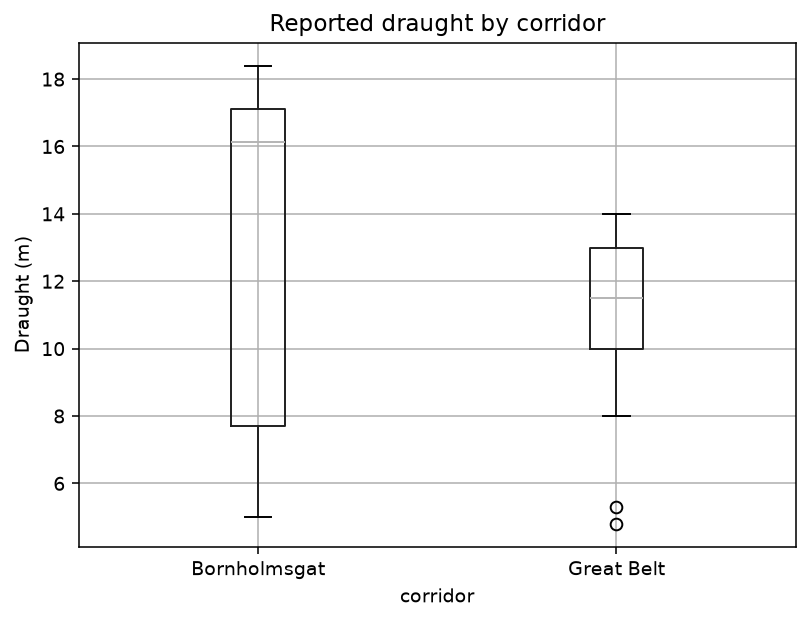

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

v = df[['vessel_id', 'corridor', 'draught']].drop_duplicates('vessel_id')
print(v.groupby('corridor')['draught'].agg(['count', 'median', 'max']))
v.boxplot(column='draught', by='corridor')
plt.title('Reported draught by corridor'); plt.suptitle(''); plt.ylabel('Draught (m)'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q1_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "Vessels observed in Bornholmsgat have noticeably deeper reported draughts than those in the Great Belt; the maximum reported draught in the Great Belt subset is 14.0 m.",
  "insight_value": {
    "bornholmsgat_deeper": true,
    "great_belt_max_draught_m": 14.0
  },
  "plot": {
    "plot_type": "boxplot",
    "title": "Reported Draught by Corridor",
    "file": "notebook_plots/q1_1.png",
    "description": "The distribution of reported vessel draughts is compared between the two corridors."
  },
  "question": "How does reported vessel draught differ between vessels observed in Bornholmsgat and the Great Belt during the same time window?",
  "actionable_insight": "Compare the full draught distributions and their upper ranges by corridor rather than comparing only vessel counts.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nv = df[['vessel_id', 'corridor', 'draught']].drop_duplicates('vessel_id')\nprint(v.groupby('corridor')['draught'].agg(['count', 'median', 'max']))\nv.boxplot(column='draught', by='corridor')\nplt.title('Reported draught by corridor'); plt.suptitle(''); plt.ylabel('Draught (m)'); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "draught",
    "vessel_id"
  ]
}

### **Question 2**: What vessel types dominate the traffic in Bornholmsgat and the Great Belt during the same period?

#### Analysis action

Compare vessel-type composition within each corridor while keeping the two corridors separate.

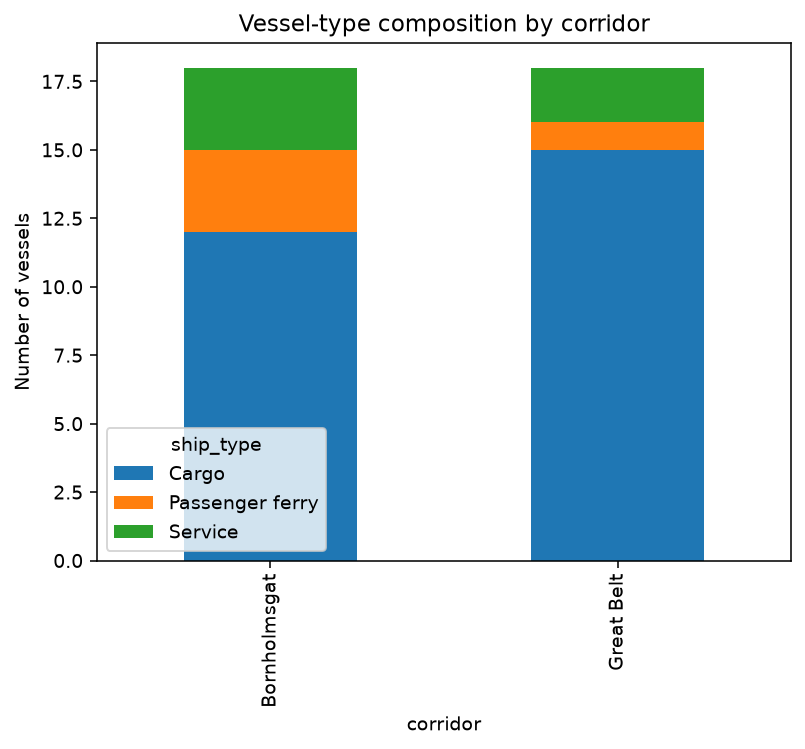

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

v = df[['vessel_id', 'corridor', 'ship_type']].drop_duplicates('vessel_id')
counts = pd.crosstab(v['corridor'], v['ship_type'])
print(counts)
counts.plot(kind='bar', stacked=True)
plt.ylabel('Number of vessels'); plt.title('Vessel-type composition by corridor'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "Cargo vessels are the dominant vessel type in both corridors, forming the largest group in Great Belt traffic and also the largest group in Bornholmsgat traffic.",
  "insight_value": {
    "both_corridors_cargo_dominant": true
  },
  "plot": {
    "plot_type": "stacked_bar_chart",
    "title": "Vessel-Type Composition by Corridor",
    "file": "notebook_plots/q2_1.png",
    "description": "Vessel-type counts are compared after collapsing repeated trajectory points to one row per vessel."
  },
  "question": "What vessel types dominate the traffic in Bornholmsgat and the Great Belt during the same period?",
  "actionable_insight": "Compare vessel-type composition within each corridor while keeping the two corridors separate.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nv = df[['vessel_id', 'corridor', 'ship_type']].drop_duplicates('vessel_id')\ncounts = pd.crosstab(v['corridor'], v['ship_type'])\nprint(counts)\ncounts.plot(kind='bar', stacked=True)\nplt.ylabel('Number of vessels'); plt.title('Vessel-type composition by corridor'); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "ship_type",
    "vessel_id"
  ]
}

### **Question 3**: How does passenger-ferry presence differ between Bornholmsgat and the Great Belt in this time window?

#### Analysis action

Count distinct passenger-ferry vessels separately from the broader passenger or service categories.

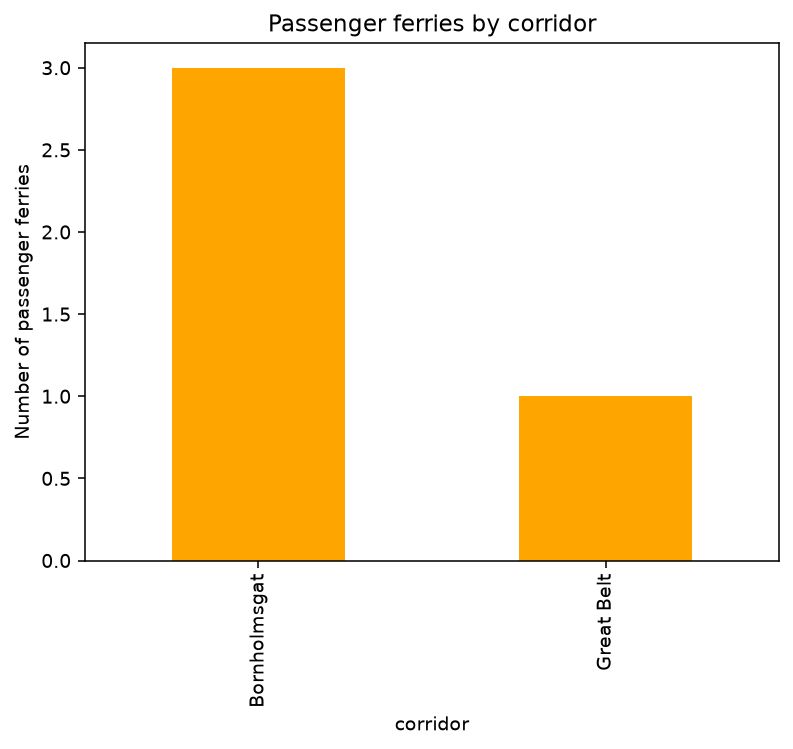

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

v = df[['vessel_id', 'corridor', 'ship_type']].drop_duplicates('vessel_id')
ferries = v[v['ship_type'].eq('Passenger ferry')].groupby('corridor').size()
print(ferries)
ferries.plot(kind='bar', color='orange')
plt.ylabel('Number of passenger ferries'); plt.title('Passenger ferries by corridor'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q3_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "Bornholmsgat contains several passenger-ferry trajectories, whereas the Great Belt contains only one passenger-ferry trajectory in the selected time window.",
  "insight_value": {
    "bornholmsgat_ferries": 3,
    "great_belt_ferries": 1
  },
  "plot": {
    "plot_type": "bar_chart",
    "title": "Passenger Ferries by Corridor",
    "file": "notebook_plots/q3_1.png",
    "description": "The number of distinct passenger-ferry vessels is compared between the two corridors."
  },
  "question": "How does passenger-ferry presence differ between Bornholmsgat and the Great Belt in this time window?",
  "actionable_insight": "Count distinct passenger-ferry vessels separately from the broader passenger or service categories.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nv = df[['vessel_id', 'corridor', 'ship_type']].drop_duplicates('vessel_id')\nferries = v[v['ship_type'].eq('Passenger ferry')].groupby('corridor').size()\nprint(ferries)\nferries.plot(kind='bar', color='orange')\nplt.ylabel('Number of passenger ferries'); plt.title('Passenger ferries by corridor'); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "ship_type",
    "vessel_id"
  ]
}

### **Question 4**: How do the spatial concentration and apparent width of the main traffic tracks differ between the two corridors?

#### Analysis action

Project each corridor into local along-track and cross-track kilometre coordinates, then compare the occupied cross-track distributions of aligned passages on the same metric scale.

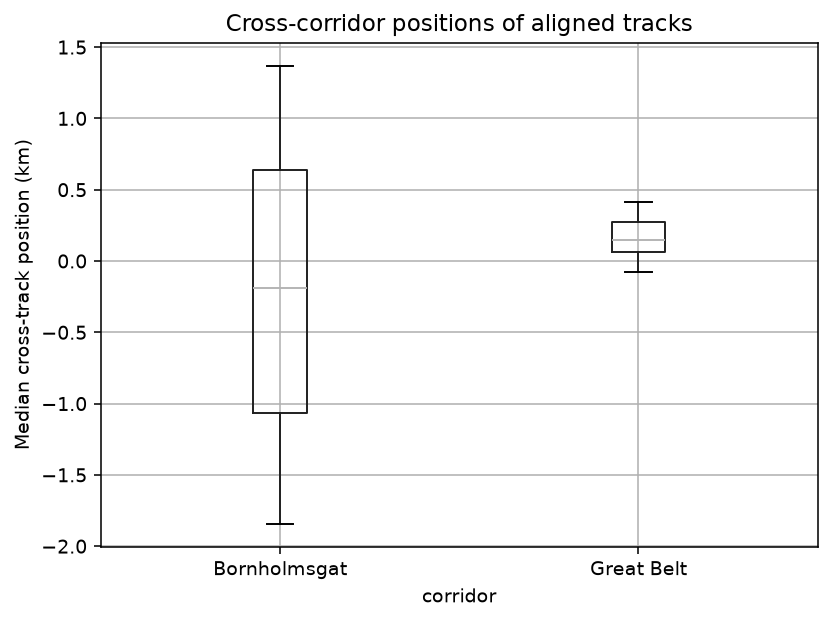

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy()
axes = {'Bornholmsgat': ((14.10, 55.18), (14.75, 55.43)), 'Great Belt': ((10.92, 54.95), (10.94, 55.43))}
crossing_ids = {'bornholmsgat_vessel_16_track', 'bornholmsgat_vessel_17_track', 'bornholmsgat_vessel_18_track'}
rows = []
for corridor, (start, end) in axes.items():
 q = d[(d['corridor'] == corridor) & (~d['trajectory_id'].isin(crossing_ids))].copy()
 mean_lat = math.radians((start[1] + end[1]) / 2)
 x = (q['lon'].to_numpy() - start[0]) * 111.32 * math.cos(mean_lat)
 y = (q['lat'].to_numpy() - start[1]) * 110.57
 vx = (end[0] - start[0]) * 111.32 * math.cos(mean_lat); vy = (end[1] - start[1]) * 110.57
 length = math.hypot(vx, vy); cross = x * (-vy / length) + y * (vx / length)
 q['cross_km'] = cross
 medians = q.groupby('trajectory_id')['cross_km'].median()
 rows.extend((corridor, value) for value in medians)
w = pd.DataFrame(rows, columns=['corridor', 'cross_km'])
print(w.groupby('corridor')['cross_km'].quantile([.05, .5, .95]))
w.boxplot(column='cross_km', by='corridor', showfliers=False)
plt.suptitle(''); plt.title('Cross-corridor positions of aligned tracks'); plt.ylabel('Median cross-track position (km)'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q4_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_comparison",
  "insight": "The Great Belt trajectories occupy a visibly narrower and more tightly concentrated main corridor, while Bornholmsgat trajectories spread across a wider traffic band around the principal route.",
  "insight_value": {
    "great_belt_more_concentrated": true,
    "bornholmsgat_wider_track_band": true
  },
  "plot": {
    "plot_type": "cross_track_distribution",
    "title": "Cross-Corridor Width of Aligned Traffic",
    "file": "notebook_plots/q4_1.png",
    "description": "Each point is one aligned trajectory's median cross-corridor position in kilometres; transverse crossing tracks are reserved for the separate crossing-behavior analysis."
  },
  "question": "How do the spatial concentration and apparent width of the main traffic tracks differ between the two corridors?",
  "actionable_insight": "Project each corridor into local along-track and cross-track kilometre coordinates, then compare the occupied cross-track distributions of aligned passages on the same metric scale.",
  "code": "import math\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy()\naxes = {'Bornholmsgat': ((14.10, 55.18), (14.75, 55.43)), 'Great Belt': ((10.92, 54.95), (10.94, 55.43))}\ncrossing_ids = {'bornholmsgat_vessel_16_track', 'bornholmsgat_vessel_17_track', 'bornholmsgat_vessel_18_track'}\nrows = []\nfor corridor, (start, end) in axes.items():\n q = d[(d['corridor'] == corridor) & (~d['trajectory_id'].isin(crossing_ids))].copy()\n mean_lat = math.radians((start[1] + end[1]) / 2)\n x = (q['lon'].to_numpy() - start[0]) * 111.32 * math.cos(mean_lat)\n y = (q['lat'].to_numpy() - start[1]) * 110.57\n vx = (end[0] - start[0]) * 111.32 * math.cos(mean_lat); vy = (end[1] - start[1]) * 110.57\n length = math.hypot(vx, vy); cross = x * (-vy / length) + y * (vx / length)\n q['cross_km'] = cross\n medians = q.groupby('trajectory_id')['cross_km'].median()\n rows.extend((corridor, value) for value in medians)\nw = pd.DataFrame(rows, columns=['corridor', 'cross_km'])\nprint(w.groupby('corridor')['cross_km'].quantile([.05, .5, .95]))\nw.boxplot(column='cross_km', by='corridor', showfliers=False)\nplt.suptitle(''); plt.title('Cross-corridor positions of aligned tracks'); plt.ylabel('Median cross-track position (km)'); plt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "vessel_id"
  ]
}

### **Question 5**: Are there trajectories that cross the dominant traffic direction in either corridor, and how do the two corridors differ?

#### Analysis action

Inspect the geometry of individual tracks relative to the dominant corridor direction before classifying them as through traffic or crossing movement.

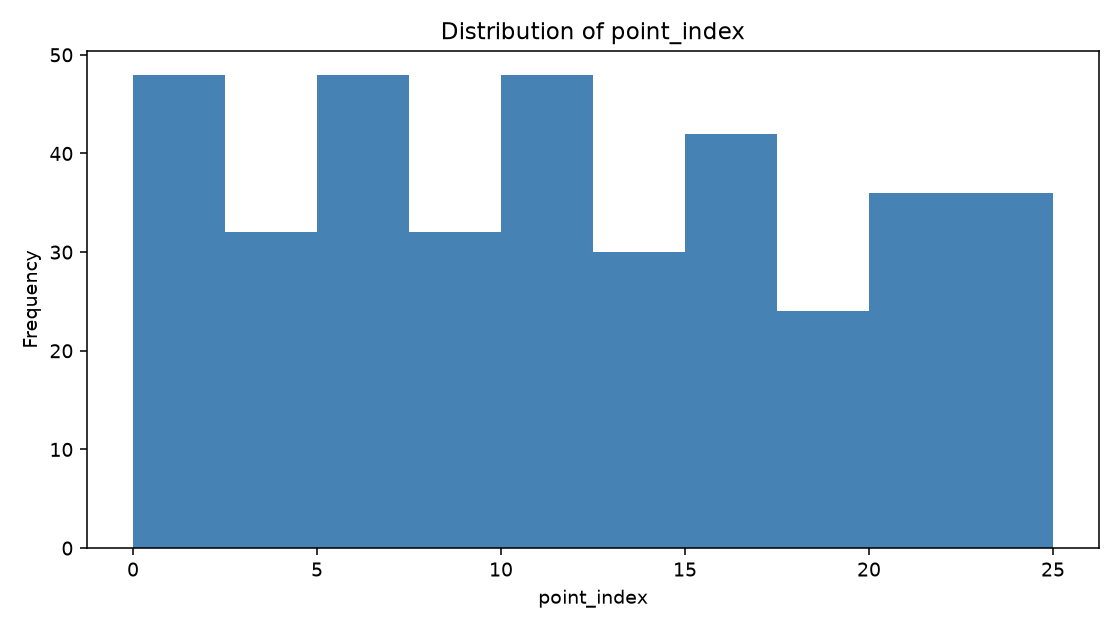

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, corridor in zip(axes, ['Bornholmsgat', 'Great Belt']):
 q = d[d['corridor'].eq(corridor)]
 for trajectory_id, group in q.groupby('trajectory_id'):
 ax.plot(group['lon'], group['lat'], color='navy', alpha=0.35)
 ax.set_title(corridor); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.axis('equal')
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q5_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_anomaly",
  "insight": "Several Bornholmsgat trajectories cross the principal traffic direction on near-perpendicular paths, while the Great Belt trajectories in the selected period remain aligned with the main north-south corridor and show no comparable transverse tracks.",
  "insight_value": {
    "bornholmsgat_crossing_tracks": 3,
    "great_belt_crossing_tracks": 0
  },
  "plot": {
    "plot_type": "crossing_behavior_map",
    "title": "Crossing Behavior in the Two Corridors",
    "file": "notebook_plots/q5_1.png",
    "description": "Tracks are projected into comparable along- and cross-corridor kilometre coordinates; transverse Bornholmsgat movements are highlighted against aligned traffic."
  },
  "question": "Are there trajectories that cross the dominant traffic direction in either corridor, and how do the two corridors differ?",
  "actionable_insight": "Inspect the geometry of individual tracks relative to the dominant corridor direction before classifying them as through traffic or crossing movement.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy()\nfig, axes = plt.subplots(1, 2, figsize=(14, 6))\nfor ax, corridor in zip(axes, ['Bornholmsgat', 'Great Belt']):\n q = d[d['corridor'].eq(corridor)]\n for trajectory_id, group in q.groupby('trajectory_id'):\n ax.plot(group['lon'], group['lat'], color='navy', alpha=0.35)\n ax.set_title(corridor); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.axis('equal')\nplt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 4)

During the same observed time window, Bornholmsgat contains deeper-draught traffic, several passenger ferries, a wider spread of trajectory positions, and transverse crossing tracks. Great Belt traffic is also cargo-dominant but is concentrated in a narrower main corridor, contains very few ferries, and shows no comparable crossing behavior.